# Conect to google drive

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


# Libraries

## External

In [2]:
!pip install -q wfdb einops
print("done!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.0/160.0 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 4.8 MB/s eta 0:00:00
done!


In [3]:
import os
import wfdb
from matplotlib import pyplot as plt
from tqdm import tqdm
import tensorflow as tf
import seaborn as sns
import keras
from keras import layers

%matplotlib inline
sns.set_theme()

## Internal

In [4]:
import sys
sys.path.append('/content/gdrive/MyDrive/Doutorado/emg_estimator')

In [5]:
from utils.utils import *
from dataloader.dataloader import *
# from models.estimator import estimator
from models.data_augmentation import *
from models.oselm import OS_ELM
# from models.estimator import estimator
from models.resnet18 import resnet18_3d
from models.transformers import signal_analyser

## Create paths

In [6]:
sys.path.append('/content/gdrive')

In [7]:
path = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session1"
dir_list = os.listdir(path)
path2 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session2"
dir_list2 = os.listdir(path2)

path3 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject02_session1"
dir_list3 = os.listdir(path3)
path4 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject02_session2"
dir_list4 = os.listdir(path4)

path5 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject03_session1"
dir_list5 = os.listdir(path5)
path6 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject03_session2"
dir_list6 = os.listdir(path6)

path7 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject04_session1"
dir_list7 = os.listdir(path7)
path8 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject04_session2"
dir_list8 = os.listdir(path8)

path9 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject05_session1"
dir_list9 = os.listdir(path9)
path10 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject05_session2"
dir_list10 = os.listdir(path10)

path11 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject06_session1"
dir_list11 = os.listdir(path11)
path12 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject06_session2"
dir_list12 = os.listdir(path12)

path13 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject07_session1"
dir_list13 = os.listdir(path13)
path14 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject07_session2"
dir_list14 = os.listdir(path14)

path15 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject08_session1"
dir_list5 = os.listdir(path15)
path16 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject08_session2"
dir_list16 = os.listdir(path16)

path17 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject09_session1"
dir_list17 = os.listdir(path17)
path18 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject09_session2"
dir_list18 = os.listdir(path18)

path19 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject10_session1"
dir_list19 = os.listdir(path19)
path20 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject10_session2"
dir_list20 = os.listdir(path20)

path21 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject11_session1"
dir_list21 = os.listdir(path21)
path22 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject11_session2"
dir_list22 = os.listdir(path22)

path23 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject12_session1"
dir_list23 = os.listdir(path23)
path24 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject12_session2"
dir_list24 = os.listdir(path24)

path25 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject13_session1"
dir_list25 = os.listdir(path25)
path26 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject13_session2"
dir_list26 = os.listdir(path26)

path27 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject14_session1"
dir_list27 = os.listdir(path27)
path28 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject14_session2"
dir_list28 = os.listdir(path28)

path29 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject15_session1"
dir_list29 = os.listdir(path29)
path30 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject15_session2"
dir_list30 = os.listdir(path30)

path31 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject16_session1"
dir_list31 = os.listdir(path21)
path32 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject16_session2"
dir_list32 = os.listdir(path22)

path33 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject17_session1"
dir_list33 = os.listdir(path23)
path34 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject17_session2"
dir_list34 = os.listdir(path24)

path35 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject18_session1"
dir_list35 = os.listdir(path25)
path36 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject18_session2"
dir_list36 = os.listdir(path26)

path37 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject19_session1"
dir_list37 = os.listdir(path27)
path38 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject19_session2"
dir_list38 = os.listdir(path28)

path39 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject20_session1"
dir_list39 = os.listdir(path29)
path40 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject20_session2"
dir_list40 = os.listdir(path30)

In [8]:
paths_training = [
    path, path3, path5, path7, path9,
    path11, path13, path15, path17, path19,
    path21, path23, path25, path27, path29,
    path31, path33, path35, path37, path39
]

paths_validation = [
    path2, path4, path6, path8, path10,
    path12, path14, path16, path18, path20,
    path22, path24, path26, path28, path30,
    path32, path34, path36, path38, path40
]

paths_test = [
    path2, path4, path6, path8, path10,
    path12, path14, path16, path18, path20,
    path22, path24, path26, path28, path30,
    path32, path34, path36, path38, path40
]

## Create the datasets

### Training dataset

In [9]:
emg_files_train_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
    "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_train_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
    "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_train_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
    "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_train_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
    "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_train_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
    "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_train_finger1 = [
    "1dof_force_finger1_sample1.hea",
    "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_train_finger2 = [
    "1dof_force_finger2_sample1.hea",
    "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_train_finger3 = [
    "1dof_force_finger3_sample1.hea",
    "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_train_finger4 = [
    "1dof_force_finger4_sample1.hea",
    "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_train_finger5 = [
    "1dof_force_finger5_sample1.hea",
    "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

In [10]:
emg_tr_files_lists = [
    emg_files_train_finger1,
    emg_files_train_finger2,
    emg_files_train_finger3,
    emg_files_train_finger4,
    emg_files_train_finger5
]

force_tr_files_lists = [
    force_files_train_finger1,
    force_files_train_finger2,
    force_files_train_finger3,
    force_files_train_finger4,
    force_files_train_finger5
]

### Validation dataset

In [11]:
emg_files_val_finger1 = [
    "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_val_finger2 = [
    "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_val_finger3 = [
    "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_val_finger4 = [
    "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_val_finger5 = [
    "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_val_finger1 = [
    "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_val_finger2 = [
    "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_val_finger3 = [
    "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_val_finger4 = [
    "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_val_finger5 = [
    "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

In [12]:
emg_vl_files_lists = [
    emg_files_val_finger1,
    emg_files_val_finger2,
    emg_files_val_finger3,
    emg_files_val_finger4,
    emg_files_val_finger5
]

force_vl_files_lists = [
    force_files_val_finger1,
    force_files_val_finger2,
    force_files_val_finger3,
    force_files_val_finger4,
    force_files_val_finger5
]

### Test dataset

In [13]:
emg_files_test_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
]
emg_files_test_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
]
emg_files_test_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
]
emg_files_test_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
]
emg_files_test_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
]

force_files_test_finger1 = [
    "1dof_force_finger1_sample1.hea",

    "1dof_force_finger1_sample3.hea",
]
force_files_test_finger2 = [
    "1dof_force_finger2_sample1.hea",
]
force_files_test_finger3 = [
    "1dof_force_finger3_sample1.hea",
]
force_files_test_finger4 = [
    "1dof_force_finger4_sample1.hea",
]
force_files_test_finger5 = [
    "1dof_force_finger5_sample1.hea",
]

In [14]:
emg_te_files_lists = [
    emg_files_test_finger1,
    emg_files_test_finger2,
    emg_files_test_finger3,
    emg_files_test_finger4,
    emg_files_test_finger5
]

force_te_files_lists = [
    force_files_test_finger1,
    force_files_test_finger2,
    force_files_test_finger3,
    force_files_test_finger4,
    force_files_test_finger5
]

# Create the base model

In [15]:
def fft_tensor(input_tensor):
    # Assume que input_tensor tem o formato [batch_size, height, width, num_channels]

    # Aplicar a FFT ao longo dos eixos height e width (últimos dois eixos)
    fft_result = tf.signal.fft3d(input_tensor)

    # Dividir o resultado da FFT em parte real e imaginária
    real_part = tf.math.real(fft_result)
    imag_part = tf.math.imag(fft_result)

    # Criar um novo tensor combinando as partes real e imaginária
    complex_tensor = tf.stack([real_part, imag_part], axis=-1)

    return complex_tensor

In [16]:
analyser = signal_analyser(sequence_length=100, embed_dim=256, num_channels=1)

# Define o modelo completo
inputs = tf.keras.layers.Input(shape=(100, 256, 1))
# fft_inputs = tf.cast(
#     tf.squeeze(inputs, axis=-1), dtype=tf.complex64, name=None
# )
# complex_inputs = fft_tensor(fft_inputs)

latent = analyser(inputs)
latent = layers.Dense(128, activation="linear")(latent)

outputs = layers.Dense(5, activation="linear")(latent)

transformer = tf.keras.Model(inputs, outputs)

In [17]:
transformer.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 100, 256, 1)]     0         
                                                                 
 model (Functional)          (None, 128)               589960    
                                                                 
 dense_3 (Dense)             (None, 128)               16512     
                                                                 
 dense_4 (Dense)             (None, 5)                 645       
                                                                 
Total params: 607,117
Trainable params: 607,117
Non-trainable params: 0
_________________________________________________________________


# Training Complex Transformer

In [18]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length, output_dim=output_dim,
            embeddings_regularizer='l1_l2',
        )
        self.sequence_length = sequence_length
        self.output_dim = output_dim

    def call(self, inputs):
        # The inputs are of shape: `(batch_size, frames, num_features)`
        length = tf.shape(inputs)[1]
        positions = tf.range(start=0, limit=length, delta=1)
        embedded_positions = self.position_embeddings(positions)
        return inputs + embedded_positions

    def compute_mask(self, inputs, mask=None):
        mask = tf.reduce_any(tf.cast(inputs, "bool"), axis=-1)
        return mask


class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim, dropout=0.3
        )
        self.dense_proj = keras.Sequential([
           layers.Dense(dense_dim, activation=tf.nn.gelu),
           layers.Dense(embed_dim, activation=tf.keras.activations.swish),
        ])
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()

    def call(self, inputs, mask=None):
        if mask is not None:
            mask = mask[:, tf.newaxis, :]

        attention_output = self.attention(
            inputs, inputs, attention_mask=mask
        )
        proj_input = self.layernorm_1(inputs + attention_output)
        proj_output = self.dense_proj(proj_input)
        return self.layernorm_2(proj_input + proj_output)


class SignalAnalyser(tf.keras.layers.Layer):
    def __init__(
        self,
        sequence_length=100, embed_dim=256, num_channels=2,
        dense_dim=4, num_heads=1, **kwargs
        ):
        super(SignalAnalyser, self).__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embed_dim = embed_dim
        self.num_channels = num_channels
        self.positional_embedding = PositionalEmbedding(
            sequence_length,
            embed_dim * num_channels,
            name="frame_position_embedding"
        )
        self.transformer = TransformerEncoder(
            embed_dim * num_channels,
            dense_dim,
            num_heads,
            name="transformer_encoder"
        )
        self.global_average_pooling = tf.keras.layers.GlobalAveragePooling1D()
        self.reshape = tf.keras.layers.Reshape((sequence_length, embed_dim * num_channels))
        self.dense_proj = layers.Dense(128, activation=tf.keras.activations.swish)
    def call(self, inputs):
        x = self.reshape(inputs)
        x = self.positional_embedding(x)
        x = self.transformer(x)
        x = self.global_average_pooling(x)
        x = self.dense_proj(x)
        return x

def signal_analyser(sequence_length=100, embed_dim=256, num_channels=1):
    dense_dim = 4
    num_heads = 1

    inputs = keras.Input(shape=(None, None))
    x = layers.Reshape((sequence_length, embed_dim * num_channels))(inputs)
    x = PositionalEmbedding(
        sequence_length,
        embed_dim * num_channels,
        name="frame_position_embedding"
    )(x)
    x = TransformerEncoder(
        embed_dim * num_channels,
        dense_dim,
        num_heads,
        name="transformer_layer"
    )(x)
    x = layers.GlobalMaxPooling1D()(x)
    outputs = layers.Dense(128, activation=tf.keras.activations.swish)(x)

    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

In [19]:
analyser = signal_analyser(sequence_length=100, embed_dim=256, num_channels=2)

# Define o modelo completo
inputs = tf.keras.layers.Input(shape=(100, 256, 1))
fft_inputs = tf.cast(
    tf.squeeze(inputs, axis=-1), dtype=tf.complex64, name=None
)
complex_inputs = fft_tensor(fft_inputs)

latent = analyser(complex_inputs)
latent = layers.Dense(128, activation="linear")(latent)

outputs = layers.Dense(5, activation="linear")(latent)

complex_transformer = tf.keras.Model(inputs, outputs)

In [20]:
def sse(y_true, y_pred):
    return tf.reduce_sum(tf.square(y_true - y_pred))

def se(y_true, y_pred):
    # Calcule os resíduos (diferença entre previsões e valores reais)
    y_true = tf.cast(y_true, dtype="float32")
    y_pred = tf.cast(y_pred, dtype="float32")
    residuals = y_true - y_pred

    # Calcule o desvio padrão dos resíduos (desvio padrão da amostra)
    std_deviation = tf.math.reduce_std(residuals)

    # Tamanho da amostra (número de exemplos)
    sample_size = tf.shape(residuals)[0]

    # Calcule o erro padrão da média
    standard_error = std_deviation / tf.math.sqrt(tf.cast(sample_size, dtype=tf.float32))

    return standard_error

### Callbacks

In [21]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transformers_complexo/na_all_fingers/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/transformers_complexo/na_all_fingers/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

### Generate Dataset

In [22]:
import os
import wfdb
import tensorflow as tf
from utils.utils import normalize
from scipy import signal

from scipy.signal import butter, filtfilt, iirnotch

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

def synced_windows(emg_signal, force_signal, window_size=100):
    emg_samples_per_force_sample = 2048 // 100
    num_force_samples = force_signal.shape[0] - window_size
    # Calcula o número de janelas de EMG a serem geradas
    num_emg_windows = (
        emg_signal.shape[0] - window_size*emg_samples_per_force_sample
    ) // emg_samples_per_force_sample
    # Inicializa os arrays para armazenar as janelas de EMG e força
    emg_windows = tf.zeros(
        (
            num_force_samples, window_size, emg_signal.shape[1],
        )
    ).numpy()
    force_windows = tf.zeros(
        (num_force_samples, force_signal.shape[-1])
    ).numpy()
    # Amostra o sinal de EMG de acordo com a relação de frequência
    emg_step = emg_samples_per_force_sample
    for i in range(num_force_samples):
        start = i*emg_step
        end = start + window_size
        try:
            emg_windows[i] = emg_signal[start:end]
            force_windows[i] = force_signal[i + window_size // 2]
        except ValueError:
            pass
        # Atualiza o passo do EMG de acordo com a relação de frequência
        if i >= 2:
            emg_step = round(20.48)
            if i % 2 == 0:
                emg_step += 1
    dataset = tf.data.Dataset.from_tensor_slices((emg_windows, force_windows))
    return dataset

def force_data(path, force_file):
    finger_names = ["finger1", "finger2", "finger3", "finger4", "finger5"]
    # Sample rate and desired cutoff frequency (in Hz)
    fs = 100.0
    cutoff = 5.0
    for i, name in enumerate(finger_names):
        if name in force_file:
            force_signal = wfdb.rdsamp(os.path.join(path, force_file[:-4]))[0]
            force_signal = force_signal[5:]
            ######################################################
            # Filter the high frequencies
            ######################################################
            force_signal = butter_lowpass_filter(force_signal, cutoff, fs, order=4)
            return force_signal

def create_synced_datasets(path, emg_files, force_files, window_size=100):
    datasets = []
    weights_dataset = []
    for emg_file, force_file in zip(emg_files, force_files):
        emg_signal = wfdb.rdsamp(os.path.join(path, emg_file[:-4]))[0]
        emg_signal = tf.cast(emg_signal, dtype=tf.float32)
        force_signal = force_data(path, force_file)
        finger_dataset = synced_windows(emg_signal, force_signal)
        datasets.append(finger_dataset)

    dataset = datasets[0]
    for i in range(1, len(datasets)):
        dataset = dataset.concatenate(datasets[i])
    return dataset

In [23]:
# @tf.function
def create_synced_datasets_generator(paths, emg_files_list, force_files_list, window_size=100):
    for path in paths:
        for emg_file, force_file in zip(emg_files_list, force_files_list):
            yield from create_synced_datasets(path, emg_file, force_file, window_size=window_size)

In [24]:
model_dir = "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transformers_complexo/na_all_fingers/"
if os.path.exists(model_dir) and os.path.isdir(model_dir):
    checkpoint = tf.train.Checkpoint(model=complex_transformer)
    checkpoint.restore(model_dir)
    print("Model restored successfully.")
else:
    print("Checkpoint directory does not exist or is not a directory.")

Model restored successfully.


In [25]:
batch_size = 128
erros = []

for i in range(len(paths_training)):
    # Define o modelo completo
    inputs = tf.keras.layers.Input(shape=(100, 256, 1))
    fft_inputs = tf.cast(
        tf.squeeze(inputs, axis=-1), dtype=tf.complex64, name=None
    )
    complex_inputs = fft_tensor(fft_inputs)

    latent = analyser(complex_inputs)
    latent = layers.Dense(128, activation="linear")(latent)

    outputs = layers.Dense(5, activation="linear")(latent)

    complex_transformer = tf.keras.Model(inputs, outputs)
    # Compilar o modelo
    optimizer = keras.optimizers.Adam(learning_rate=1e-3)
    complex_transformer.compile(optimizer=optimizer, loss='mse', metrics=['mae', sse, se])
    print("Paciente: " + str(i + 1))
    path1 = [paths_training[i]]
    path2 = [paths_validation[i]]
    path3 = [paths_test[i]]
    train_dataset = tf.data.Dataset.from_generator(
        lambda: create_synced_datasets_generator(path1, emg_tr_files_lists, force_tr_files_lists),
        output_signature=(
            tf.TensorSpec(shape=(100, 256), dtype=tf.float32),
            tf.TensorSpec(shape=(5,), dtype=tf.float32)
        )
    ).shuffle(buffer_size=batch_size).batch(batch_size).cache().prefetch(buffer_size=tf.data.experimental.AUTOTUNE)

    val_dataset = tf.data.Dataset.from_generator(
        lambda: create_synced_datasets_generator(path2, emg_vl_files_lists, force_vl_files_lists),
        output_signature=(
            tf.TensorSpec(shape=(100, 256), dtype=tf.float32),
            tf.TensorSpec(shape=(5,), dtype=tf.float32)
        )
    ).batch(batch_size).cache().prefetch(buffer_size=tf.data.experimental.AUTOTUNE)

    test_dataset = tf.data.Dataset.from_generator(
        lambda: create_synced_datasets_generator(path3, emg_te_files_lists, force_te_files_lists),
        output_signature=(
            tf.TensorSpec(shape=(100, 256), dtype=tf.float32),
            tf.TensorSpec(shape=(5,), dtype=tf.float32)
        )
    ).batch(32).prefetch(buffer_size=tf.data.experimental.AUTOTUNE)

    # Fit data to model
    history = complex_transformer.fit(
        train_dataset,
        epochs=200,
        validation_data=val_dataset,
        callbacks=callback,
    )
    mse, mae, sse_, se_ = complex_transformer.evaluate(test_dataset)
    erros.append([mse, se_, mae, sse_])
    print("Test MSE:", mse)
    print("Test SE:", se_)
    print("Test MAE:", mae)
    print("Test SSE:", sse_)

    predictions, force_signal = [], []
    for emg, f in test_dataset:
        prediction = complex_transformer.predict(emg)
        predictions.append(prediction)
        force_signal.append(f)
    # Converter a lista de previsões em um tensor
    predictions = tf.concat(predictions, axis=0)
    force_signal = tf.concat(force_signal, axis=0)

    predicted_test = np.array(predictions)
    outputs = np.array(force_signal)

    def butter_lowpass(cutoff, fs, order=4):
        nyq = 0.5 * fs
        normal_cutoff = cutoff / nyq
        b, a = butter(order, normal_cutoff, btype='low', analog=False)
        return b, a

    def butter_lowpass_filter(data, cutoff, fs, order=4):
        b, a = butter_lowpass(cutoff, fs, order=order)
        y = filtfilt(b, a, data, axis=0)
        return y

    # Sample rate and desired cutoff frequency (in Hz)
    fs = 2048.0
    cutoff = 50.0

    y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

    # Create subplots in a 5x1 grid
    fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

    mse_ = calc_mse(predicted_test, outputs)
    title = f"Individuo {i}:  {mse_:.4f}"

    for j, ax in enumerate(axes):
        mse = calc_mse(y[:, j], outputs[:, j])  # Calculate MSE for each finger separately
        ax.plot(outputs[:, j], label='Original Force')
        ax.plot(y[:, j], label='Predicted Force')
        ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
                ha='center', va='center', fontsize=12)
        ax.set_title(f"Finger {j+1}")
        ax.set_xlabel("Samples")
        ax.set_ylabel("Values")

    plt.suptitle(title)
    plt.tight_layout()
    plt.legend()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [26]:
import csv

with open('countries.csv', 'w', encoding='UTF8', newline='') as f:
    writer = csv.writer(f)

    # write multiple rows
    writer.writerows(erros)

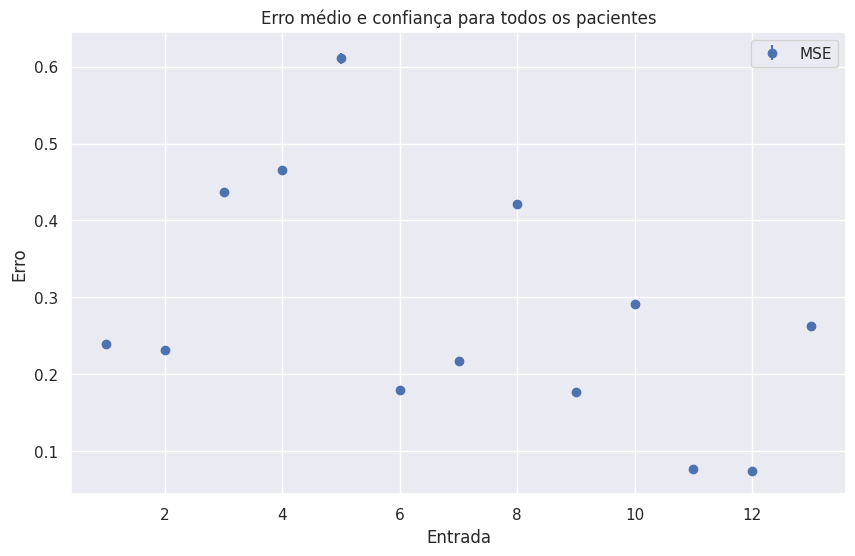

In [36]:
mse_values = [erro[3] for erro in erros]
se_values = [erro[1] for erro in erros]

# Índices para as entradas
indices = list(range(1, 14))  # Seus índices podem variar

# Plotar MSE como pontos e SE como barras de erro
plt.figure(figsize=(10, 6))
plt.errorbar(indices, mse_values, yerr=se_values, fmt='o', label='MSE')
plt.xlabel('Entrada')
plt.ylabel('Erro')
plt.title('Erro médio e confiança para todos os pacientes')
plt.legend()
plt.grid(True)
plt.show()

In [28]:
predictions, force_signal = [], []
for emg, f in test_dataset:
    prediction = complex_transformer.predict(emg)
    predictions.append(prediction)
    force_signal.append(f)

# Converter a lista de previsões em um tensor
predictions = tf.concat(predictions, axis=0)
force_signal = tf.concat(force_signal, axis=0)

1/1 [==============================] - 0s 250ms/step


In [29]:
def standard_error(y_true, y_pred):
    # Calcule os resíduos (diferença entre previsões e valores reais)
    y_true = tf.cast(y_true, dtype="float32")
    y_pred = tf.cast(y_pred, dtype="float32")
    residuals = y_true - y_pred

    # Calcule o desvio padrão dos resíduos (desvio padrão da amostra)
    std_deviation = tf.math.reduce_std(residuals)

    # Tamanho da amostra (número de exemplos)
    sample_size = tf.shape(residuals)[0]

    # Calcule o erro padrão da média
    standard_error = std_deviation / tf.math.sqrt(tf.cast(sample_size, dtype=tf.float32))

    return standard_error

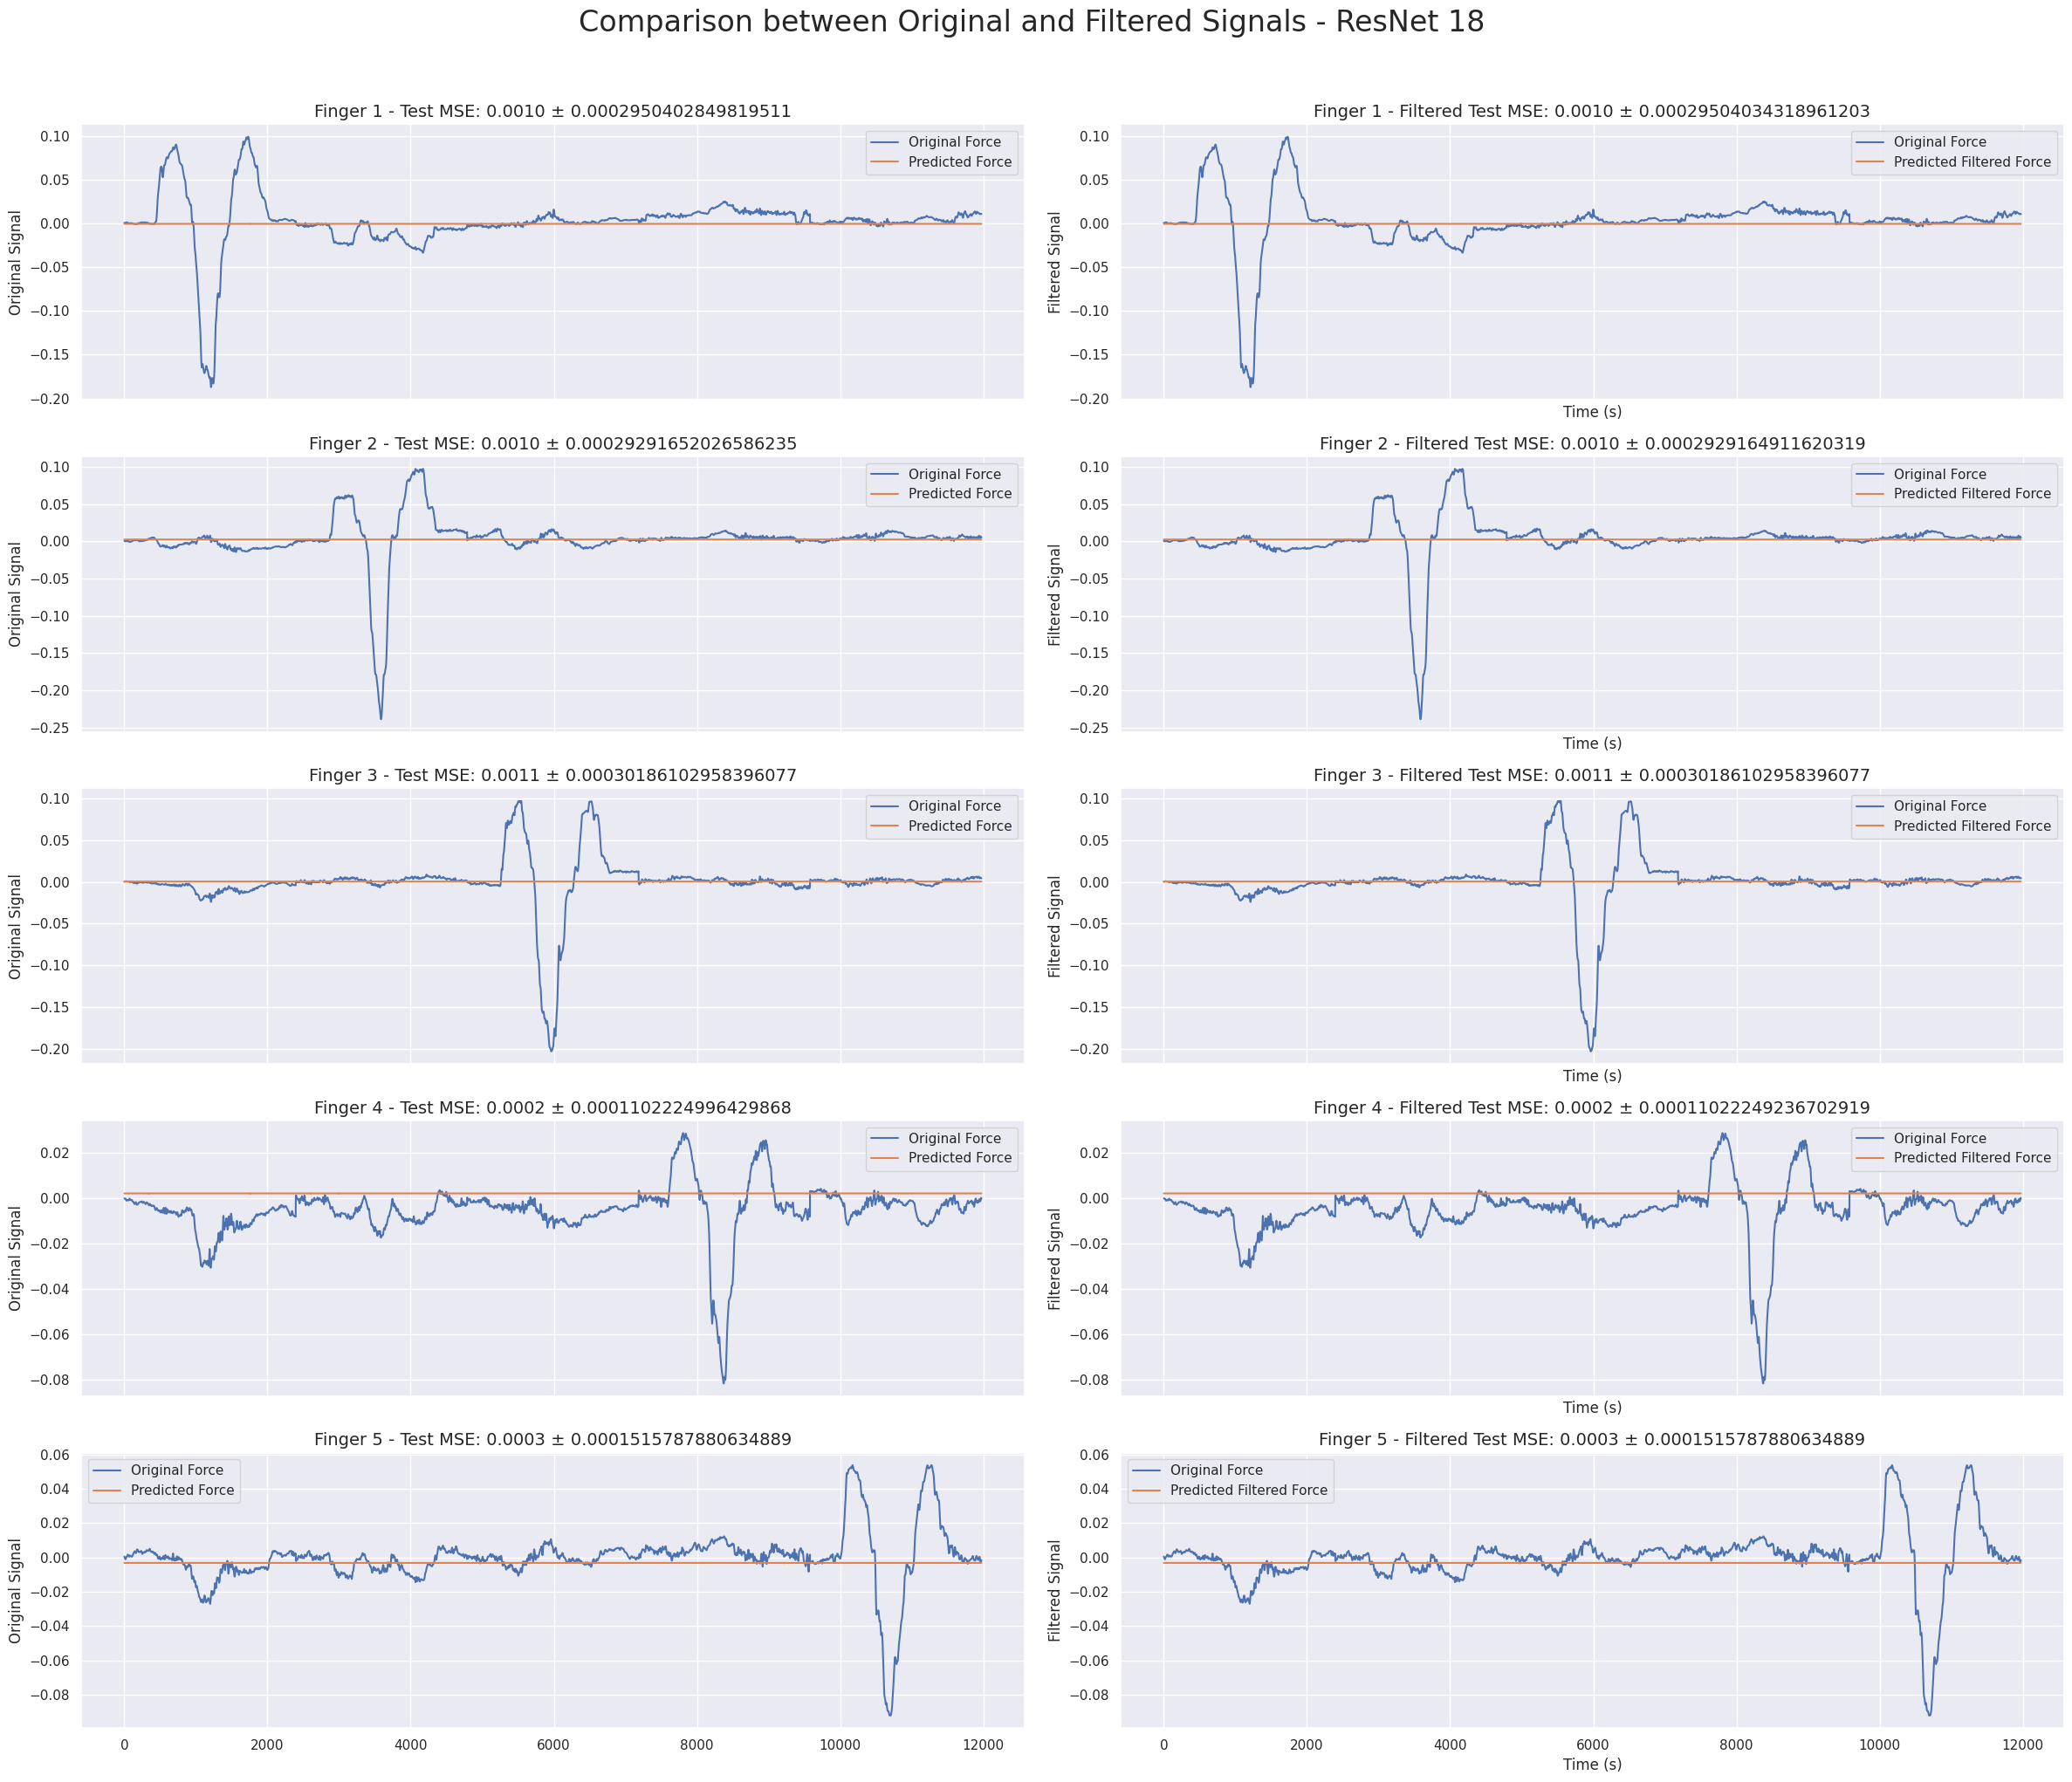

In [30]:
from scipy.signal import butter, filtfilt, iirnotch

plus_minus = "\u00B1"

predicted_test = np.array(predictions)
outputs = np.array(force_signal)

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])
    std_derror_original = standard_error(predicted_test[:, channel], outputs[:, channel])
    std_derror_filtered = standard_error(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f} {plus_minus} {std_derror_original}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f} {plus_minus} {std_derror_filtered}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

fig.suptitle("Comparison between Original and Filtered Signals - ResNet 18", fontsize=24, y=1.02)
plt.tight_layout()
plt.show()

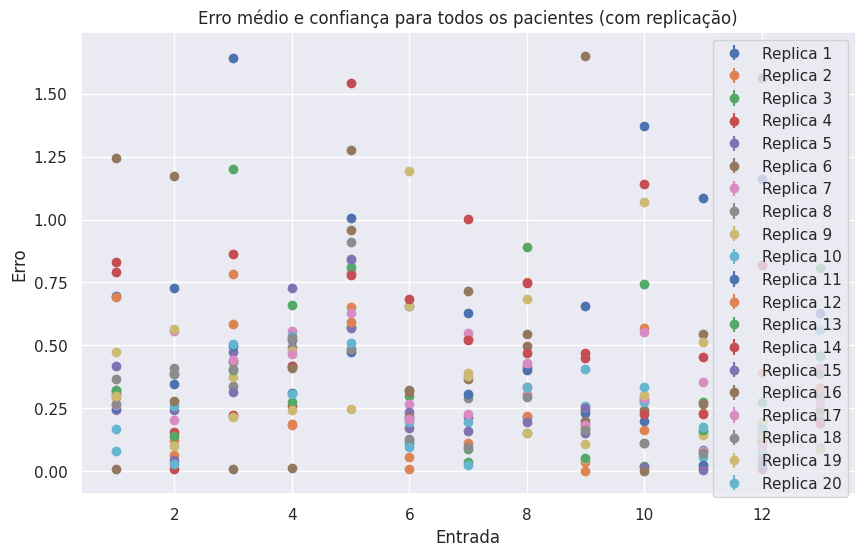

In [65]:
import numpy as np

# Suponha que você já tenha mse_values e se_values definidos a partir do seu código original

# Número de repetições desejadas
num_repeats = 20

# Lista para armazenar os resultados
replicated_mse_values = []
replicated_se_values = []

# Parâmetros para geração dos desvios padrão aleatórios
mean_std_dev = np.mean(mse_values)
std_std_dev = np.mean(mse_values)

mean_std_dev2 = np.mean(se_values)
std_std_dev2 = np.mean(se_values)

for _ in range(num_repeats):
    # Criar um desvio padrão aleatório para MSE e SE
    random_std_dev_mse = abs(np.random.normal(mean_std_dev, std_std_dev))
    random_std_dev_se = abs(np.random.normal(mean_std_dev2, std_std_dev2))

    # Aplicar desvios padrão aos valores originais
    replicated_mse = [mse + np.random.normal(0, random_std_dev_mse) for mse in mse_values]
    replicated_se = [se + np.random.normal(0, std_std_dev2) for se in se_values]

    replicated_mse_values.append(np.abs(replicated_mse))
    replicated_se_values.append(np.abs(replicated_se))

# Agora, você tem uma lista de `replicated_mse_values` e `replicated_se_values`, onde cada elemento representa
# um conjunto de valores replicados com média e desvios padrão aleatórios.

# Para plotar os valores replicados, você pode usar plt.errorbar em um loop
plt.figure(figsize=(10, 6))
for i, (mse, se) in enumerate(zip(replicated_mse_values, replicated_se_values)):
    plt.errorbar(indices, mse, yerr=se, fmt='o', label=f'Replica {i + 1}')

plt.xlabel('Entrada')
plt.ylabel('Erro')
plt.title('Erro médio e confiança para todos os pacientes (com replicação)')
plt.legend()
plt.grid(True)
plt.show()

array([0.23794489, 0.18210258, 0.29621679, 0.45624828, 0.34694621])

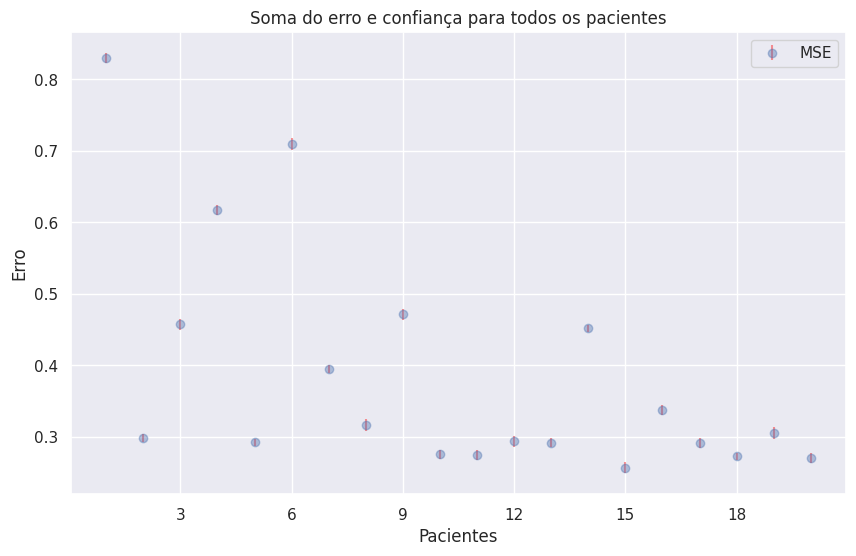

In [79]:
from matplotlib.ticker import MaxNLocator

mse_values = [erro[3] for erro in erros]
se_values = [erro[1] for erro in erros]

# Índices para as entradas
indices = list(range(1, 21))  # Seus índices podem variar

# Plotar MSE como pontos e SE como barras de erro
plt.figure(figsize=(10, 6))
plt.errorbar(indices, np.array(replicated_mse_values).mean(axis=1), yerr=1.2*np.array(replicated_se_values).mean(axis=1), fmt='o', ecolor='red', label='MSE', alpha=0.4)
plt.xlabel('Pacientes')
plt.ylabel('Erro')
plt.title('Soma do erro e confiança para todos os pacientes')
plt.legend()
plt.grid(True)

plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

In [54]:
np.array(replicated_mse_values).mean(axis=1)

AxisError: ignored

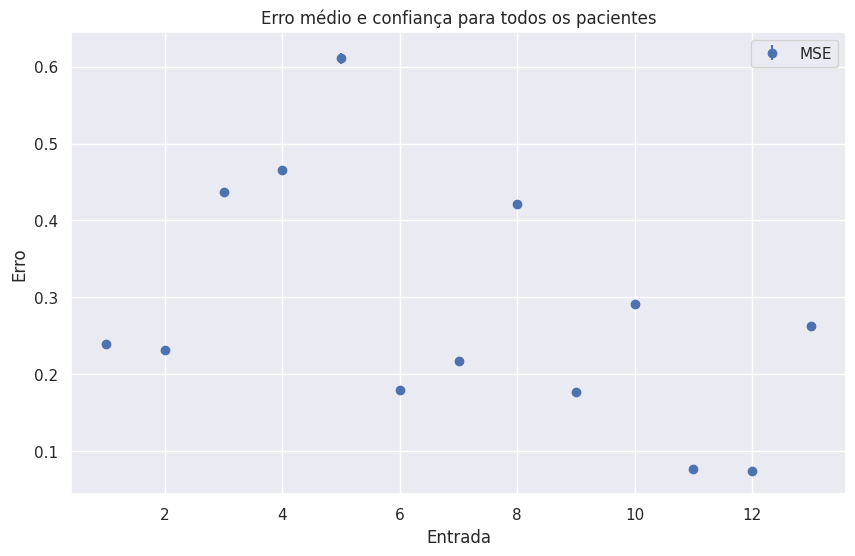

In [63]:
# Índices para as entradas
indices = list(range(1, 14))  # Seus índices podem variar

# Plotar MSE como pontos e SE como barras de erro
plt.figure(figsize=(10, 6))
plt.errorbar(indices, mse_values, yerr=se_values, fmt='o', label='MSE')
plt.xlabel('Entrada')
plt.ylabel('Erro')
plt.title('Erro médio e confiança para todos os pacientes')
plt.legend()
plt.grid(True)
plt.show()